# U3-E1 — Análisis y caracterización de la serie de tiempo
## Observatorio del Precio del Limón en Colima

- **Responsable:** Integrante 1 — Análisis y caracterización (Naomi Alvarez)
- **Fecha:** 28 de noviembre de 2026
- **Fuente:** `data/oro/oro_serie_mensual_observatorio.parquet` (Capa Oro, E3)
- **Figuras:** `evidencias/U3E1/` · **Datasets preparados:** `data/series_tiempo/`

### Objetivo
Preparar y caracterizar la serie mensual del precio mayorista del limón con semilla en Colima,
diagnosticar su estacionariedad, analizar su autocorrelación y medir su correlación cruzada con el
clima (Open-Meteo). Los resultados sirven al Integrante 2 para construir y justificar los modelos ARIMA/SARIMA.

### Contenido
1. Preparación de datos
2. Variable objetivo y frecuencia
3. Gráfica y caracterización
4. Tendencia, estacionalidad y atípicos
5. Descomposición (aditiva vs. multiplicativa)
6. Prueba de Dickey-Fuller aumentada (ADF)
7. Diferenciación y nueva comprobación
8. ACF y PACF
9. Correlación cruzada con el clima
10. Datasets preparados
11. Resumen para el Integrante 2
12. Limitaciones

> Todos los valores citados en las interpretaciones provienen de las salidas de las celdas de este cuaderno.
> No se generaron ni imputaron datos nuevos.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf, ccf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Raíz del repositorio (funciona desde docs/U3-E1 o desde la raíz)
RAIZ = Path.cwd()
while not (RAIZ / "data" / "oro").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
FIG_DIR = RAIZ / "evidencias" / "U3E1"
DATA_OUT = RAIZ / "data" / "series_tiempo"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_OUT.mkdir(parents=True, exist_ok=True)

matplotlib.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})
MESES = {1: "Ene", 2: "Feb", 3: "Mar", 4: "Abr", 5: "May", 6: "Jun",
         7: "Jul", 8: "Ago", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dic"}

def formato_fechas(ax):
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))

print("Raíz del repositorio:", RAIZ)

Raíz del repositorio: C:\Users\naomi\OneDrive\Documentos\Ingenieria de Datos\Observatorio-limon\observatorio-limon-colima


## 1. Preparación de datos
Se revisa el dataset Oro: duplicados, faltantes, continuidad del calendario y orden cronológico.

In [2]:
panel = pd.read_parquet(RAIZ / "data" / "oro" / "oro_serie_mensual_observatorio.parquet")
panel["anio_mes"] = pd.to_datetime(panel["anio_mes"])
panel = panel.sort_values(["estado", "anio_mes"]).reset_index(drop=True)

print(f"Panel Oro: {panel.shape[0]} filas x {panel.shape[1]} columnas")
print("Estados:", sorted(panel["estado"].unique()))
print("Filas completamente duplicadas:", int(panel.duplicated().sum()))
print("Duplicados de la clave estado + anio_mes:", int(panel.duplicated(["estado", "anio_mes"]).sum()))
print("\nObservaciones por estado:")
print(panel.groupby("estado")["anio_mes"].agg(["count", "min", "max"]))

Panel Oro: 137 filas x 55 columnas
Estados: ['colima', 'guerrero', 'michoacan', 'sinaloa', 'yucatan']
Filas completamente duplicadas: 0
Duplicados de la clave estado + anio_mes: 0

Observaciones por estado:
           count        min        max
estado                                
colima        33 2024-02-01 2026-10-01
guerrero      29 2024-07-01 2026-11-01
michoacan     37 2023-11-01 2026-11-01
sinaloa       37 2023-11-01 2026-11-01
yucatan        1 2026-02-01 2026-02-01


In [3]:
# Serie focal: Colima, ordenada cronológicamente con frecuencia mensual explícita
colima = panel[panel["estado"] == "colima"].set_index("anio_mes").sort_index()
calendario = pd.date_range(colima.index.min(), colima.index.max(), freq="MS")
print("Orden cronológico correcto:", colima.index.is_monotonic_increasing)
print("Meses esperados:", len(calendario), "| meses presentes:", len(colima),
      "| huecos:", len(calendario.difference(colima.index)))
colima = colima.asfreq("MS")
y = colima["precio_frec_media"]

vars_clave = ["precio_frec_media", "precio_min", "precio_max", "temp_media_c", "precipitacion_mm"]
print("\nFaltantes en variables clave:")
print(colima[vars_clave].isna().sum())

print("\nMeses con pocas cotizaciones (< 10):")
print(colima.loc[colima["n_cotizaciones"] < 10, ["precio_frec_media", "n_cotizaciones"]])

# Periodos de precio sin cambio (mismo valor en 3 o más meses seguidos)
bloques = (y != y.shift()).cumsum()
rachas = y.groupby(bloques).agg(["first", "size"])
rachas.index = [y[bloques == b].index[0].strftime("%Y-%m") for b in rachas.index]
print("\nPeriodos con precio constante (>= 3 meses):")
for inicio, fila in rachas[rachas["size"] >= 3].iterrows():
    tramo = colima.loc[inicio:].head(int(fila["size"]))
    print(f"  desde {inicio}: {fila['first']:.2f} $/kg durante {int(fila['size'])} meses, "
          f"cotizaciones por mes: {tramo['n_cotizaciones'].tolist()}")

Orden cronológico correcto: True
Meses esperados: 33 | meses presentes: 33 | huecos: 0

Faltantes en variables clave:
precio_frec_media    0
precio_min           0
precio_max           0
temp_media_c         0
precipitacion_mm     0
dtype: int64

Meses con pocas cotizaciones (< 10):
            precio_frec_media  n_cotizaciones
anio_mes                                     
2024-02-01              18.42               4
2024-06-01              21.05               7
2026-10-01              20.53               4

Periodos con precio constante (>= 3 meses):
  desde 2025-05: 21.05 $/kg durante 5 meses, cotizaciones por mes: [20, 20, 23, 21, 21]
  desde 2026-08: 20.53 $/kg durante 3 meses, cotizaciones por mes: [21, 21, 4]


**Interpretación — preparación**

- El panel Oro tiene **137 filas**, **0 filas duplicadas** y **0 duplicados de la clave `estado + anio_mes`**, así que no hubo que eliminar registros.
- La serie de Colima va de **febrero 2024 a octubre 2026 (33 meses)**, está en orden cronológico y **no tiene huecos ni faltantes** en precio, temperatura ni precipitación. No fue necesario imputar.
- **Meses parciales:** febrero 2024 y octubre 2026 tienen solo **4 cotizaciones** cada uno (junio 2024 tiene 7), así que su promedio es menos confiable. Se conservan para no romper la continuidad mensual que necesitan ADF, ACF y ARIMA, y se documentan como limitación.
- **Precio constante:** el precio se queda en **21.05 $/kg de mayo a septiembre 2025** y en **20.53 $/kg de agosto a octubre 2026**. **No son datos imputados:** esos meses tienen entre 20 y 23 cotizaciones reales. El SNIIM simplemente reportó el mismo precio frecuente. Se conservan tal cual.

## 2. Variable objetivo y frecuencia

| Atributo | Valor |
|---|---|
| Variable objetivo | `precio_frec_media`: precio mayorista **frecuente** del limón con semilla (\$/kg), promedio mensual de cotizaciones SNIIM |
| Columna de fecha | `anio_mes` (primer día del mes) |
| Frecuencia | Mensual, inicio de mes (`MS`) |
| Estado focal | Colima (Tecomán) |
| Cobertura | Febrero 2024 – Octubre 2026 · 33 observaciones |

Se elige el precio *frecuente* porque es la moda del mercado (más robusta que el mínimo o el máximo), es la variable de interés del observatorio y ya pasó la puerta de calidad Pandera de E2.

## 3. Gráfica y caracterización de la serie

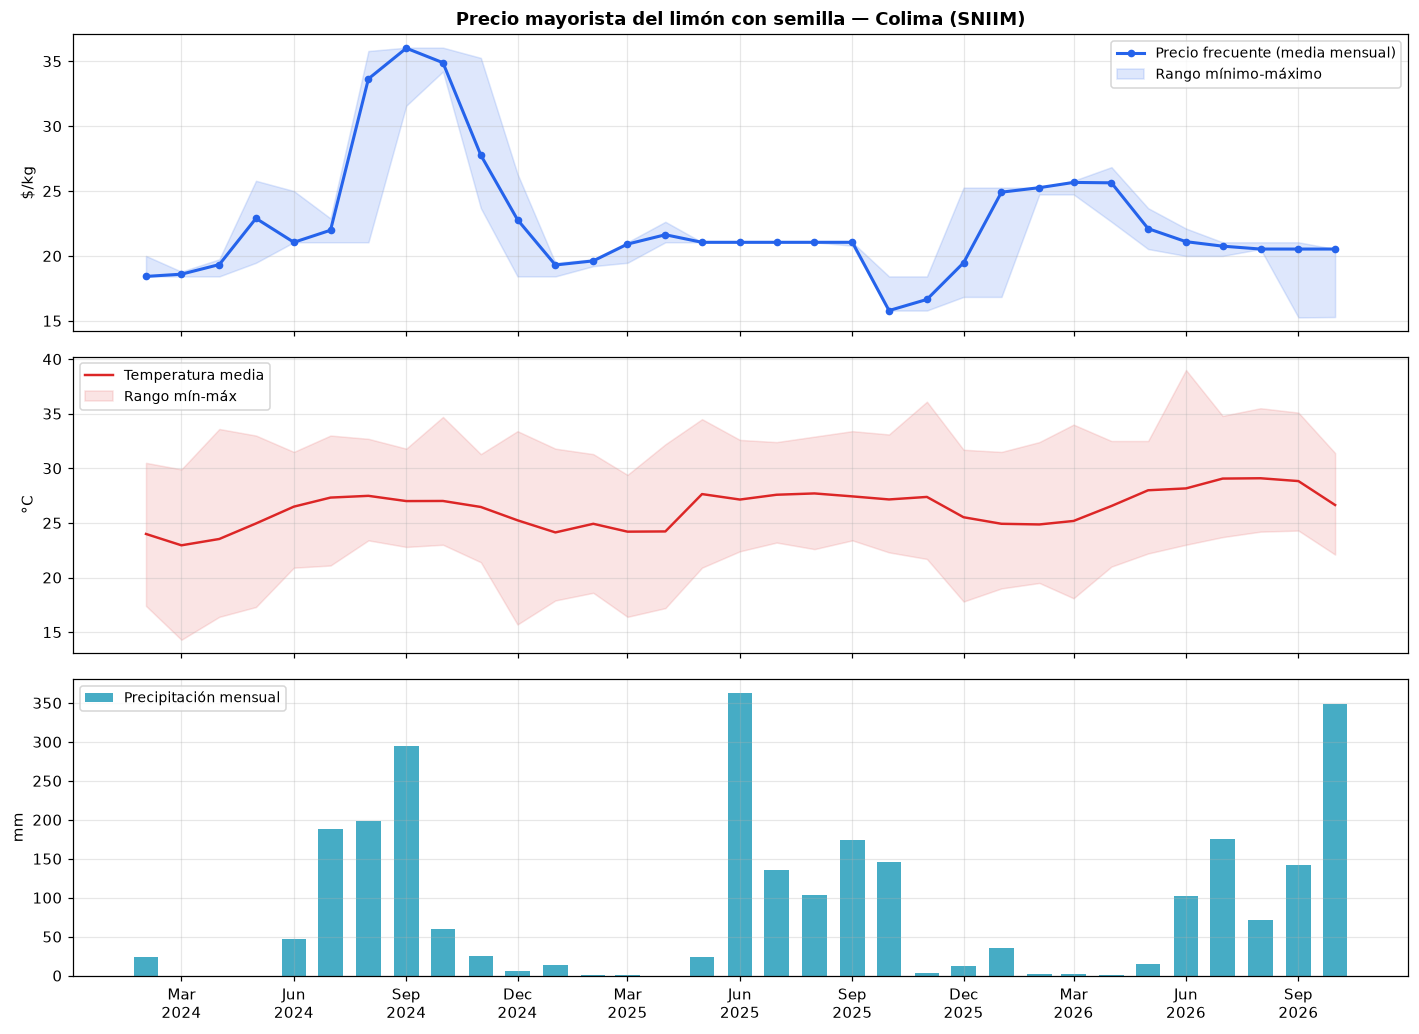

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9.5), sharex=True)
axes[0].plot(y.index, y, color="#2563EB", lw=2, marker="o", ms=4, label="Precio frecuente (media mensual)")
axes[0].fill_between(y.index, colima["precio_min"], colima["precio_max"], color="#2563EB", alpha=0.15, label="Rango mínimo-máximo")
axes[0].set_ylabel("$/kg")
axes[0].set_title("Precio mayorista del limón con semilla — Colima (SNIIM)", fontweight="bold")
axes[0].legend(fontsize=9)
axes[1].plot(y.index, colima["temp_media_c"], color="#DC2626", lw=1.6, label="Temperatura media")
axes[1].fill_between(y.index, colima["temp_min_c"], colima["temp_max_c"], color="#DC2626", alpha=0.12, label="Rango mín-máx")
axes[1].set_ylabel("°C")
axes[1].legend(fontsize=9)
axes[2].bar(y.index, colima["precipitacion_mm"], width=20, color="#0891B2", alpha=0.75, label="Precipitación mensual")
axes[2].set_ylabel("mm")
axes[2].legend(fontsize=9)
for ax in axes:
    formato_fechas(ax)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig01_serie_precio_clima.png", bbox_inches="tight")
plt.show()

In [5]:
print("Estadísticos descriptivos del precio (Colima)")
print(f"  Media:          {y.mean():.3f} $/kg")
print(f"  Mediana:        {y.median():.3f} $/kg")
print(f"  Desv. estándar: {y.std():.3f} $/kg")
print(f"  CV:             {y.std() / y.mean() * 100:.1f} %")
print(f"  Mínimo:         {y.min():.3f} $/kg ({y.idxmin():%b %Y})")
print(f"  Máximo:         {y.max():.3f} $/kg ({y.idxmax():%b %Y})")
print(f"  Asimetría:      {y.skew():.3f}")
print(f"  Curtosis:       {y.kurt():.3f}")
w, p_sw = stats.shapiro(y)
print(f"  Shapiro-Wilk:   W = {w:.4f}, p = {p_sw:.4f}")
print("\nMedia y dispersión por año:")
print(y.groupby(y.index.year).agg(["mean", "std", "min", "max", "count"]).round(3))

Estadísticos descriptivos del precio (Colima)
  Media:          22.516 $/kg
  Mediana:        21.050 $/kg
  Desv. estándar: 4.688 $/kg
  CV:             20.8 %
  Mínimo:         15.790 $/kg (Oct 2025)
  Máximo:         36.009 $/kg (Sep 2024)
  Asimetría:      1.667
  Curtosis:       2.722
  Shapiro-Wilk:   W = 0.8082, p = 0.0000

Media y dispersión por año:
            mean    std    min     max  count
anio_mes                                     
2024      25.216  6.718  18.42  36.009     11
2025      19.885  1.876  15.79  21.633     12
2026      22.702  2.349  20.53  25.664     10


**Interpretación — caracterización**

- Precio medio de **22.52 \$/kg** (mediana 21.05) con desviación estándar de **4.69 \$/kg** (CV = 20.8 %).
- El máximo es **36.01 \$/kg en septiembre 2024** y el mínimo **15.79 \$/kg en octubre 2025**.
- La distribución tiene **asimetría positiva (1.67)**: hay pocos meses muy caros y muchos meses en torno a 20–22 \$/kg. Shapiro-Wilk rechaza la normalidad (p < 0.001).
- El nivel cambia por año: **2024 promedia 25.22 \$/kg con mucha dispersión (σ = 6.72)**, **2025 baja a 19.89 (σ = 1.88)** y **2026 sube a 22.70 (σ = 2.35)**.

## 4. Tendencia, estacionalidad y valores atípicos

Q1 = 20.530, Q3 = 22.895, IQR = 2.365 -> límites [16.983, 26.441]
Atípicos IQR: 6
  Aug 2024: 33.646 $/kg (cotizaciones: 22)
  Sep 2024: 36.009 $/kg (cotizaciones: 19)
  Oct 2024: 34.891 $/kg (cotizaciones: 22)
  Nov 2024: 27.764 $/kg (cotizaciones: 20)
  Oct 2025: 15.790 $/kg (cotizaciones: 23)
  Nov 2025: 16.647 $/kg (cotizaciones: 19)
Cotizaciones atípicas marcadas por Hampel en el pipeline (n_atipicos > 0): {Timestamp('2026-01-01 00:00:00'): 1}


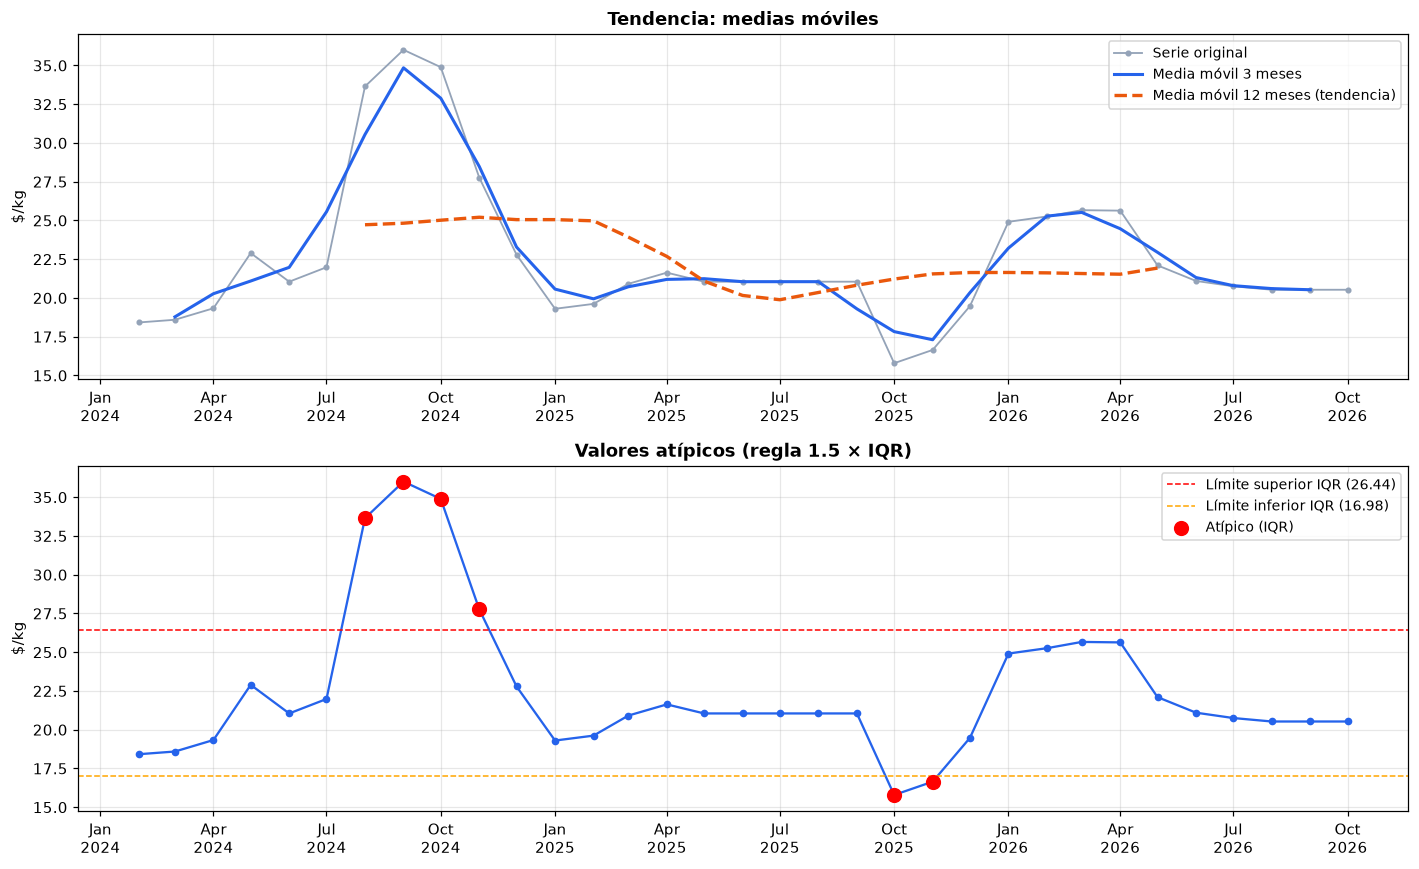

In [6]:
media_3 = y.rolling(3, center=True).mean()
media_12 = y.rolling(12, center=True).mean()
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
atipicos = y[(y < lim_inf) | (y > lim_sup)]

fig, axes = plt.subplots(2, 1, figsize=(13, 8))
axes[0].plot(y.index, y, color="#94A3B8", lw=1.2, marker="o", ms=3, label="Serie original")
axes[0].plot(media_3.index, media_3, color="#2563EB", lw=2, label="Media móvil 3 meses")
axes[0].plot(media_12.index, media_12, color="#EA580C", lw=2.2, ls="--", label="Media móvil 12 meses (tendencia)")
axes[0].set_title("Tendencia: medias móviles", fontweight="bold")
axes[0].set_ylabel("$/kg")
axes[0].legend(fontsize=9)
axes[1].plot(y.index, y, color="#2563EB", lw=1.5, marker="o", ms=4)
axes[1].axhline(lim_sup, color="red", ls="--", lw=1, label=f"Límite superior IQR ({lim_sup:.2f})")
axes[1].axhline(lim_inf, color="orange", ls="--", lw=1, label=f"Límite inferior IQR ({lim_inf:.2f})")
axes[1].scatter(atipicos.index, atipicos, color="red", s=80, zorder=5, label="Atípico (IQR)")
axes[1].set_title("Valores atípicos (regla 1.5 × IQR)", fontweight="bold")
axes[1].set_ylabel("$/kg")
axes[1].legend(fontsize=9)
for ax in axes:
    formato_fechas(ax)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig02_tendencia_atipicos.png", bbox_inches="tight")
plt.show()

print(f"Q1 = {q1:.3f}, Q3 = {q3:.3f}, IQR = {iqr:.3f} -> límites [{lim_inf:.3f}, {lim_sup:.3f}]")
print(f"Atípicos IQR: {len(atipicos)}")
for fecha, valor in atipicos.items():
    print(f"  {fecha:%b %Y}: {valor:.3f} $/kg (cotizaciones: {colima.loc[fecha, 'n_cotizaciones']})")
print("Cotizaciones atípicas marcadas por Hampel en el pipeline (n_atipicos > 0):",
      colima.loc[colima["n_atipicos"] > 0, "n_atipicos"].to_dict())

Colima — precio por mes (filas) y año (columnas):
anio   2024   2025   2026
mes                      
Ene     NaN  19.30  24.91
Feb   18.42  19.62  25.26
Mar   18.59  20.91  25.66
Abr   19.33  21.63  25.63
May   22.89  21.05  22.10
Jun   21.05  21.05  21.10
Jul   21.98  21.05  20.75
Ago   33.65  21.05  20.53
Sep   36.01  21.05  20.53
Oct   34.89  15.79  20.53
Nov   27.76  16.65    NaN
Dic   22.79  19.47    NaN


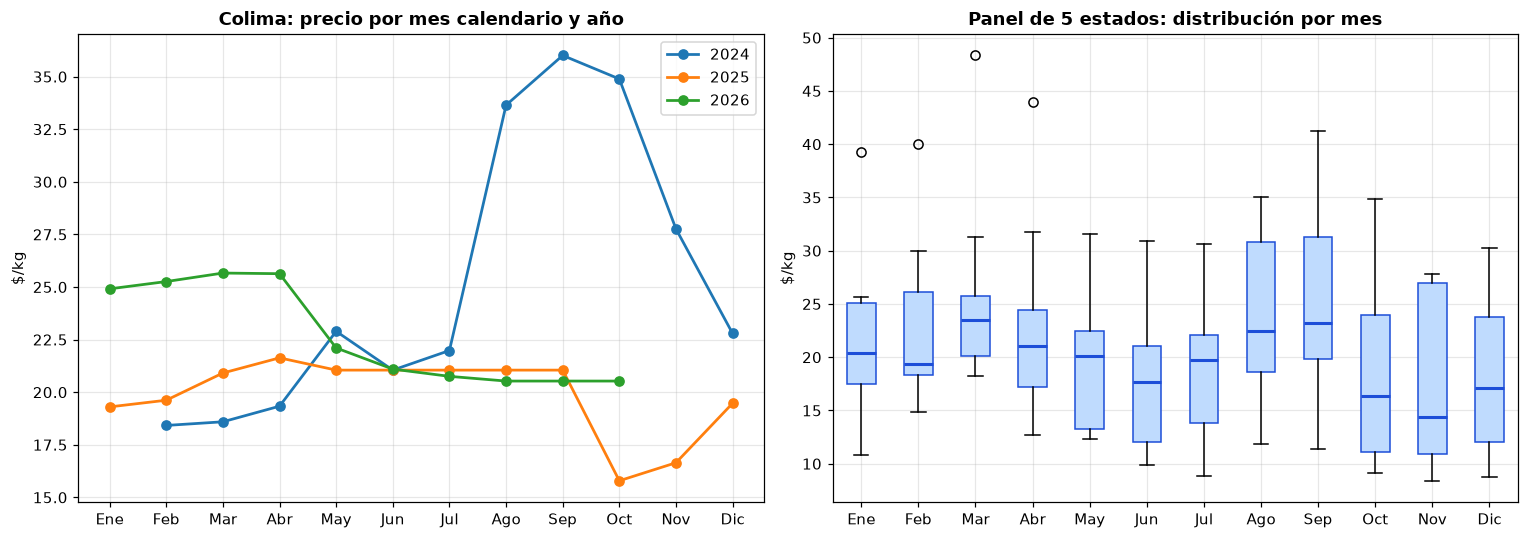

In [7]:
# Estacionalidad: precio por mes calendario, una línea por año (Colima) y boxplot del panel
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tabla_mes = y.to_frame("precio").assign(anio=y.index.year, mes=y.index.month)
for anio, grupo in tabla_mes.groupby("anio"):
    axes[0].plot(grupo["mes"], grupo["precio"], marker="o", lw=1.8, label=str(anio))
axes[0].set_xticks(range(1, 13), [MESES[m] for m in range(1, 13)])
axes[0].set_ylabel("$/kg")
axes[0].set_title("Colima: precio por mes calendario y año", fontweight="bold")
axes[0].legend()

panel_lim = panel[panel["anio_mes"] >= "2024-02-01"].copy()
panel_lim["mes"] = panel_lim["anio_mes"].dt.month
datos_box = [panel_lim.loc[panel_lim["mes"] == m, "precio_frec_media"].values for m in range(1, 13)]
axes[1].boxplot(datos_box, tick_labels=[MESES[m] for m in range(1, 13)], patch_artist=True,
                boxprops=dict(facecolor="#BFDBFE", color="#1D4ED8"), medianprops=dict(color="#1D4ED8", lw=2))
axes[1].set_ylabel("$/kg")
axes[1].set_title("Panel de 5 estados: distribución por mes", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig03_estacionalidad.png", bbox_inches="tight")
plt.show()

print("Colima — precio por mes (filas) y año (columnas):")
print(tabla_mes.pivot(index="mes", columns="anio", values="precio").rename(index=MESES).round(2))

**Interpretación — tendencia, estacionalidad y atípicos**

- **Tendencia:** no hay una tendencia creciente ni decreciente sostenida. La media móvil de 12 meses muestra **cambios de nivel**: un nivel alto en 2024, un descenso en 2025 y una recuperación parcial en 2026. Con menos de tres años no se puede afirmar una tendencia de largo plazo.
- **Estacionalidad:** en 2024 hay un pico fuerte en **agosto–octubre**, pero ese patrón **no se repite igual**. En 2025 esos meses se quedan en 21.05 \$/kg y el mínimo cae en octubre. En 2026 el máximo aparece en **enero–abril** (≈ 25 \$/kg). La estacionalidad anual es **débil e inestable** con la información disponible.
- **Atípicos (IQR):** 6 meses. Agosto–noviembre 2024 son atípicos altos (un episodio de precios elevados) y octubre–noviembre 2025 son atípicos bajos. Todos tienen entre 19 y 23 cotizaciones, por lo que **son movimientos reales del mercado, no errores**. Se conservan; eliminarlos rompería la serie. A nivel de cotización diaria, el filtro Hampel del pipeline marcó solo 1 cotización atípica (enero 2026).

## 5. Descomposición: ¿aditiva o multiplicativa?
La decisión se toma con evidencia: si la dispersión crece con el nivel de la serie, el modelo multiplicativo es más adecuado.
Se calculan ambas y se comparan.

Spearman entre media móvil y desviación móvil (ventana 6): rho = 0.626, p = 0.0004
Desv. estándar del residuo — aditiva: 4.7286 $/kg | multiplicativa: 4.6056 $/kg

Factores estacionales (multiplicativa):
  Ene: 0.996 (-0.4 %)
  Feb: 0.897 (-10.3 %)
  Mar: 0.943 (-5.7 %)
  Abr: 0.984 (-1.6 %)
  May: 0.986 (-1.4 %)
  Jun: 0.961 (-3.9 %)
  Jul: 0.970 (-3.0 %)
  Ago: 1.142 (+14.2 %)
  Sep: 1.163 (+16.3 %)
  Oct: 1.052 (+5.2 %)
  Nov: 0.971 (-2.9 %)
  Dic: 0.937 (-6.3 %)

Tendencia (multiplicativa): 20.02 -> 29.35 $/kg


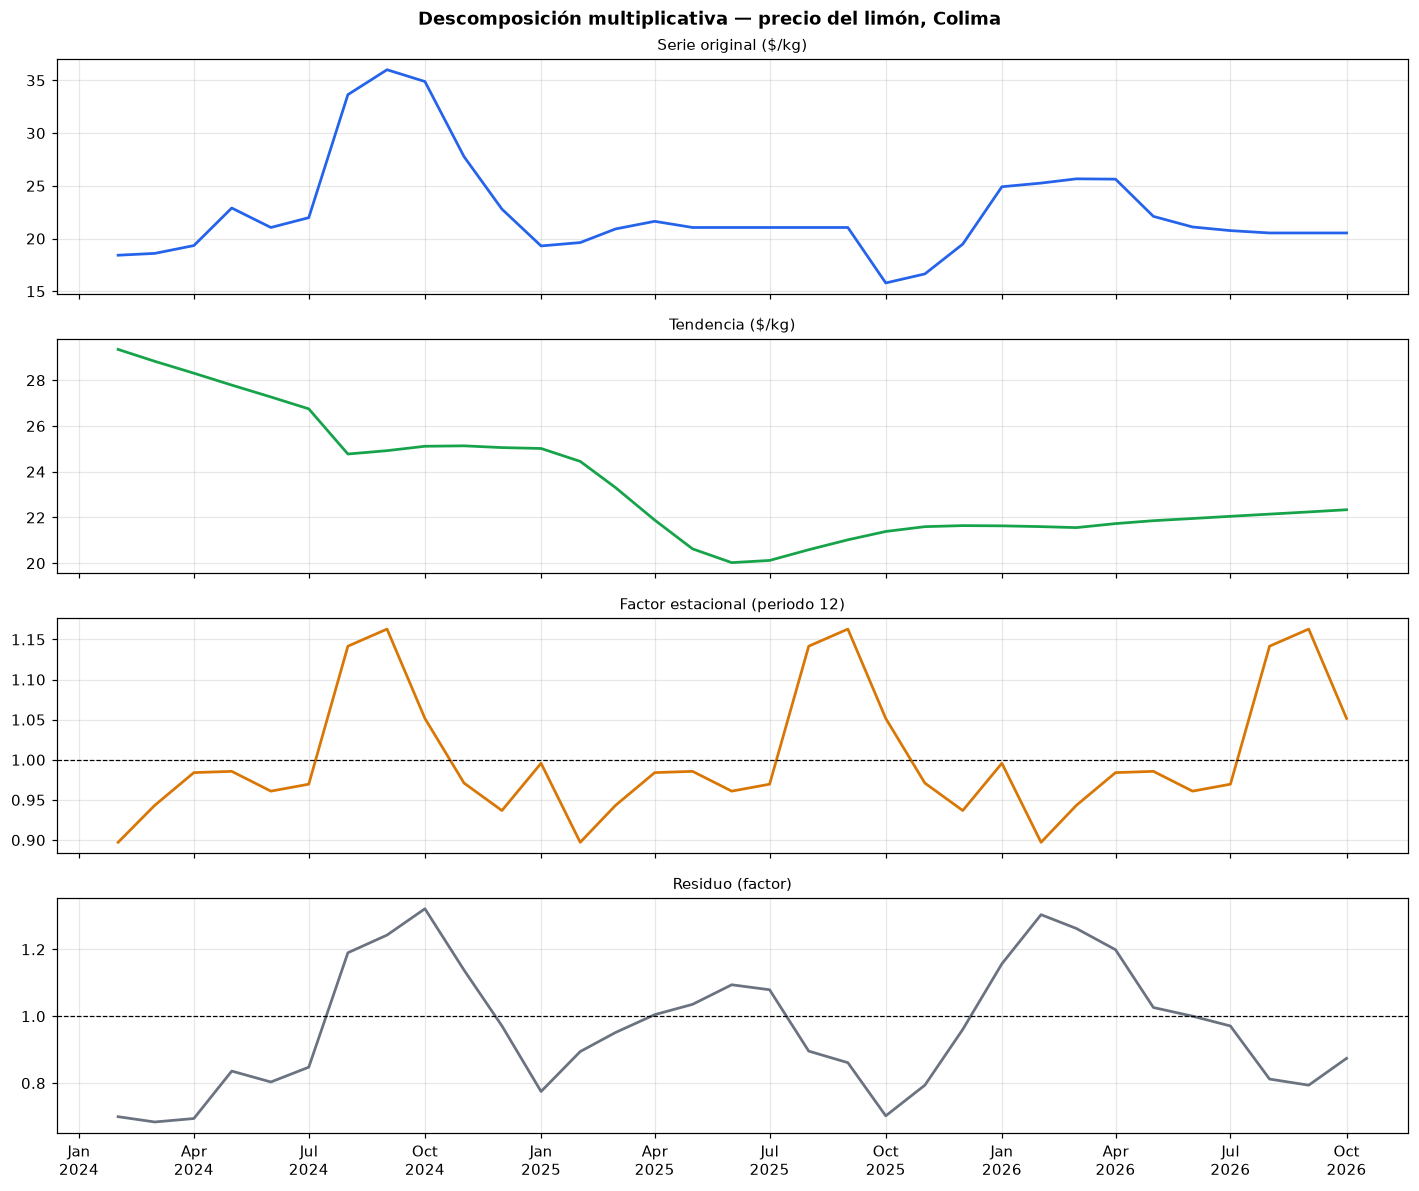

In [8]:
media_movil = y.rolling(6).mean()
desv_movil = y.rolling(6).std()
ok = media_movil.notna()
rho, p_rho = stats.spearmanr(media_movil[ok], desv_movil[ok])
print(f"Spearman entre media móvil y desviación móvil (ventana 6): rho = {rho:.3f}, p = {p_rho:.4f}")

desc_add = seasonal_decompose(y, model="additive", period=12, extrapolate_trend="freq")
desc_mul = seasonal_decompose(y, model="multiplicative", period=12, extrapolate_trend="freq")
resid_add = desc_add.resid
resid_mul_pesos = (desc_mul.resid - 1) * desc_mul.trend   # residuo multiplicativo expresado en $/kg
print(f"Desv. estándar del residuo — aditiva: {resid_add.std():.4f} $/kg | multiplicativa: {resid_mul_pesos.std():.4f} $/kg")

factores = desc_mul.seasonal.groupby(desc_mul.seasonal.index.month).first()
print("\nFactores estacionales (multiplicativa):")
for m, f in factores.items():
    print(f"  {MESES[m]}: {f:.3f} ({(f - 1) * 100:+.1f} %)")
print(f"\nTendencia (multiplicativa): {desc_mul.trend.min():.2f} -> {desc_mul.trend.max():.2f} $/kg")

fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True)
partes = [(y, "Serie original ($/kg)", "#2563EB"),
          (desc_mul.trend, "Tendencia ($/kg)", "#16A34A"),
          (desc_mul.seasonal, "Factor estacional (periodo 12)", "#D97706"),
          (desc_mul.resid, "Residuo (factor)", "#6B7280")]
for ax, (serie, titulo, color) in zip(axes, partes):
    ax.plot(serie.index, serie, color=color, lw=1.8)
    ax.set_title(titulo, fontsize=10)
    formato_fechas(ax)
axes[2].axhline(1, color="black", lw=0.8, ls="--")
axes[3].axhline(1, color="black", lw=0.8, ls="--")
fig.suptitle("Descomposición multiplicativa — precio del limón, Colima", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig04_descomposicion_multiplicativa.png", bbox_inches="tight")
plt.show()

**Justificación — se elige la descomposición multiplicativa**

1. **La dispersión crece con el nivel:** la correlación de Spearman entre la media móvil y la desviación móvil es **ρ = 0.626 (p = 0.0004)**. Por ejemplo, en 2024 (media 25.22 \$/kg) la desviación fue 6.72, y en 2025 (media 19.89) fue solo 1.88. Esta es justamente la condición que pide un modelo multiplicativo.
2. **Ajuste ligeramente mejor:** el residuo multiplicativo, expresado en \$/kg, tiene una desviación de **4.61** contra **4.73** del aditivo.
3. **Resultado:** los factores estacionales indican precios **14 % arriba en agosto (1.142) y 16 % arriba en septiembre (1.163)**, y **10 % abajo en febrero (0.897)**. La tendencia va de 20.0 a 29.3 \$/kg.

**Precaución:** con 33 meses cada factor mensual se estima con solo 2 o 3 observaciones, y el pico de agosto–septiembre viene sobre todo del episodio de 2024. La relación entre dispersión y nivel también depende en gran parte de ese episodio. Los factores deben leerse como **descriptivos**, no como un patrón confirmado. Las dos descomposiciones coinciden en la forma del ciclo, así que esta conclusión no depende de la elección.

## 6. Prueba de Dickey-Fuller aumentada (ADF)

- **H₀:** la serie tiene raíz unitaria, es decir, **no es estacionaria**.
- **H₁:** la serie **es estacionaria** (no tiene raíz unitaria).
- **Regla:** se rechaza H₀ si el estadístico ADF es menor que el valor crítico, o si p < 0.05.

El número de rezagos se elige por AIC. Se prueba con constante (`c`) y con constante más tendencia (`ct`). Como **confirmación** se aplica KPSS, cuyas hipótesis son las inversas (H₀: la serie es estacionaria).

In [9]:
def prueba_adf(serie, nombre, regresion="c"):
    est, p, rezagos, nobs, criticos, _ = adfuller(serie.dropna(), autolag="AIC", regression=regresion)
    print(f"ADF — {nombre} (regresión '{regresion}')")
    print(f"  Estadístico = {est:.4f} | p-valor = {p:.6f} | rezagos = {rezagos} | observaciones = {nobs}")
    for nivel, valor in criticos.items():
        print(f"  Valor crítico {nivel:>3}: {valor:.4f}  {'-> rechaza H0' if est < valor else ''}")
    print(f"  Conclusión (alfa = 0.05): {'estacionaria' if p < 0.05 else 'NO estacionaria'}\n")
    return {"estadistico": est, "p": p, "rezagos": rezagos, "criticos": criticos, "estacionaria": p < 0.05}

adf_c = prueba_adf(y, "precio original", "c")
adf_ct = prueba_adf(y, "precio original", "ct")

kpss_est, kpss_p, kpss_rez, kpss_crit = kpss(y, regression="c", nlags="auto")
print("KPSS — precio original (H0: estacionaria)")
print(f"  Estadístico = {kpss_est:.4f} | p-valor >= {kpss_p:.2f} | rezagos = {kpss_rez} | crítico 5% = {kpss_crit['5%']:.3f}")
print(f"  Conclusión: {'no se rechaza estacionariedad' if kpss_p >= 0.05 else 'se rechaza estacionariedad'}")

ADF — precio original (regresión 'c')
  Estadístico = -3.3209 | p-valor = 0.013971 | rezagos = 1 | observaciones = 31
  Valor crítico  1%: -3.6614  
  Valor crítico  5%: -2.9605  -> rechaza H0
  Valor crítico 10%: -2.6193  -> rechaza H0
  Conclusión (alfa = 0.05): estacionaria

ADF — precio original (regresión 'ct')
  Estadístico = -3.5245 | p-valor = 0.036837 | rezagos = 1 | observaciones = 31
  Valor crítico  1%: -4.2849  
  Valor crítico  5%: -3.5630  
  Valor crítico 10%: -3.2153  -> rechaza H0
  Conclusión (alfa = 0.05): estacionaria

KPSS — precio original (H0: estacionaria)
  Estadístico = 0.1245 | p-valor >= 0.10 | rezagos = 3 | crítico 5% = 0.463
  Conclusión: no se rechaza estacionariedad


**Interpretación — ADF**

- **ADF con constante:** estadístico **−3.3209**, menor que el crítico al 5 % (−2.9605), con **p = 0.0140**. **Se rechaza H₀**: la serie es estacionaria al 5 %. *No* se rechaza al 1 % (crítico −3.6614), así que la evidencia es buena pero no contundente.
- **ADF con constante y tendencia:** estadístico **−3.5245**. Queda justo por encima del crítico de muestra finita al 5 % (−3.5630) y por debajo del crítico al 10 % (−3.2153). El p-valor aproximado (MacKinnon) es **0.0368**. Es un resultado **limítrofe**: rechaza H₀ al 10 % y, por p-valor, al 5 %. Agregar una tendencia no cambia la conclusión, pero tampoco la refuerza. Como la serie no muestra una tendencia sostenida (punto 4), la especificación principal es la de solo constante.
- **KPSS:** estadístico **0.1245**, por debajo del crítico al 5 % (0.463), con p ≥ 0.10. **No se rechaza la estacionariedad.**
- **Conclusión:** ADF y KPSS **coinciden**. La serie en niveles es estacionaria en media; los cambios de nivel por año no alcanzan a ser una raíz unitaria.

## 7. Diferenciación y nueva comprobación

In [10]:
if adf_c["estacionaria"] and kpss_p >= 0.05:
    d = 0
    print("d = 0: la serie ya es estacionaria (ADF y KPSS coinciden). No se diferencia.")
else:
    d = 1
    print("d = 1: se aplica primera diferencia.")

# Solo como referencia: qué pasaría al diferenciar sin necesidad
dy = y.diff().dropna()
adf_d1 = prueba_adf(dy, "primera diferencia (solo referencia)", "c")

d = 0: la serie ya es estacionaria (ADF y KPSS coinciden). No se diferencia.
ADF — primera diferencia (solo referencia) (regresión 'c')
  Estadístico = -3.8091 | p-valor = 0.002816 | rezagos = 0 | observaciones = 31
  Valor crítico  1%: -3.6614  -> rechaza H0
  Valor crítico  5%: -2.9605  -> rechaza H0
  Valor crítico 10%: -2.6193  -> rechaza H0
  Conclusión (alfa = 0.05): estacionaria



**Interpretación — diferenciación**

- **No se aplica diferenciación (d = 0).** La serie original ya pasa ADF (p = 0.0140) y KPSS (p ≥ 0.10).
- Como no se transformó la serie, la "nueva comprobación" es la confirmación con KPSS y con ADF con tendencia del punto 6. Las dos sostienen la estacionariedad.
- La primera diferencia se muestra **solo como referencia** (ADF = −3.8091, p = 0.0028). Que también sea estacionaria **no justifica usarla**. Diferenciar una serie que ya es estacionaria (sobrediferenciación) elimina la información del nivel medio al que la serie regresa (≈ 22.4 \$/kg) y agrega una raíz unitaria a la parte MA del modelo, lo que lo vuelve no invertible y empeora los pronósticos.
- **Para el Integrante 2: usar d = 0** (ARIMA(p, 0, q) con constante).

## 8. Funciones de autocorrelación (ACF) y autocorrelación parcial (PACF)
Se calculan hasta el **rezago 15** para poder revisar el **rezago 12** (estacionalidad anual). Es el máximo que admite la PACF con n = 33 (debe ser menor que n/2).

n = 33 | banda PACF (95 %) = ±0.3412 | ACF con bandas de Bartlett
           ACF  ACF_significativa    PACF  PACF_significativa
rezago                                                       
1       0.7502               True  0.7502                True
2       0.3447              False -0.4989                True
3      -0.0141              False -0.0836               False
4      -0.2178              False -0.0009               False
5      -0.3091              False -0.1528               False
6      -0.3209              False -0.0673               False
7      -0.2239              False  0.1287               False
8      -0.1254              False -0.1792               False
9      -0.0246              False  0.0788               False
10      0.0098              False -0.1210               False
11     -0.0493              False -0.2218               False
12     -0.1801              False -0.1661               False
13     -0.2660              False  0.0239               False
14  

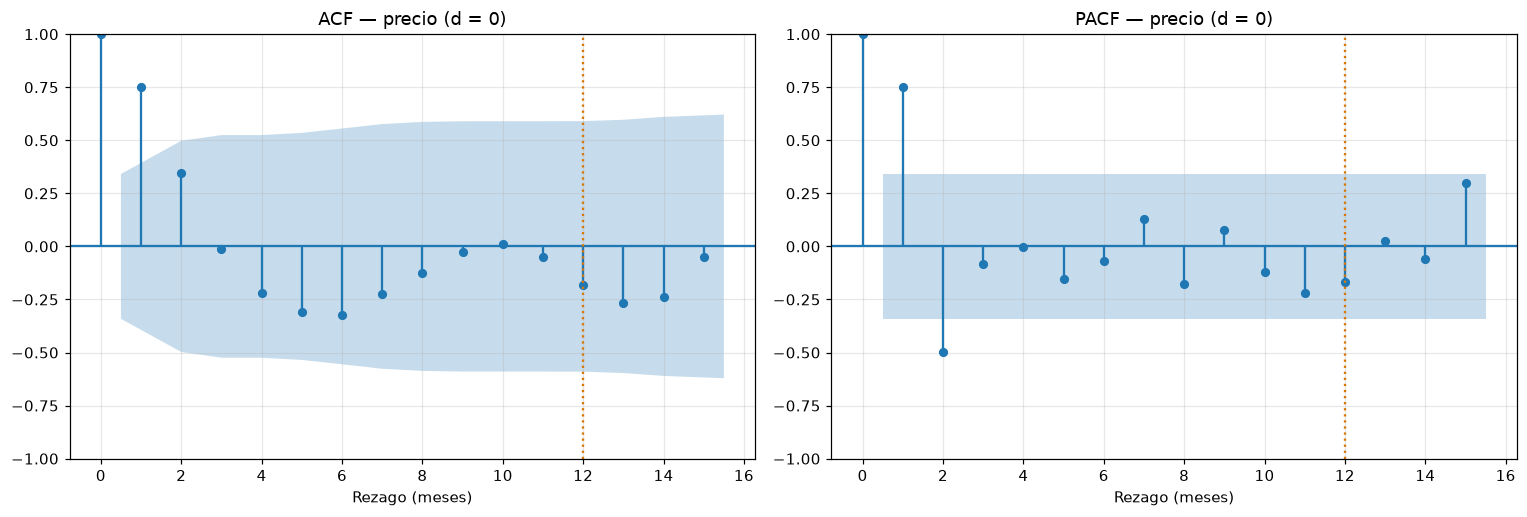

In [11]:
serie_modelo = y if d == 0 else y.diff().dropna()
n = len(serie_modelo)
MAX_LAG = 15
banda = 1.96 / np.sqrt(n)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
plot_acf(serie_modelo, lags=MAX_LAG, alpha=0.05, ax=axes[0], title=f"ACF — precio (d = {d})")
plot_pacf(serie_modelo, lags=MAX_LAG, alpha=0.05, method="ywm", ax=axes[1], title=f"PACF — precio (d = {d})")
for ax in axes:
    ax.set_xlabel("Rezago (meses)")
    ax.axvline(12, color="#D97706", ls=":", lw=1.5)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig05_acf_pacf.png", bbox_inches="tight")
plt.show()

valores_acf, ic_acf = acf(serie_modelo, nlags=MAX_LAG, alpha=0.05)
valores_pacf = pacf(serie_modelo, nlags=MAX_LAG, method="ywm")
tabla_acf = pd.DataFrame({
    "ACF": valores_acf[1:],
    "ACF_significativa": [abs(valores_acf[k]) > (ic_acf[k, 1] - valores_acf[k]) for k in range(1, MAX_LAG + 1)],
    "PACF": valores_pacf[1:],
    "PACF_significativa": np.abs(valores_pacf[1:]) > banda,
}, index=pd.RangeIndex(1, MAX_LAG + 1, name="rezago")).round(4)
print(f"n = {n} | banda PACF (95 %) = ±{banda:.4f} | ACF con bandas de Bartlett")
print(tabla_acf)

In [12]:
# Verificación orientativa de los órdenes identificados (la selección final le corresponde al Integrante 2)
candidatos = [(1, 0, 0), (2, 0, 0), (1, 0, 1), (2, 0, 1), (0, 0, 1)]
filas = []
for orden in candidatos:
    ajuste = ARIMA(serie_modelo, order=orden).fit()
    filas.append({"orden": str(orden), "AIC": ajuste.aic, "BIC": ajuste.bic})
print(pd.DataFrame(filas).sort_values("AIC").round(2).to_string(index=False))

ar2 = ARIMA(serie_modelo, order=(2, 0, 0)).fit()
print("\nParámetros ARIMA(2,0,0):")
print(ar2.params.round(4))
lb = acorr_ljungbox(ar2.resid, lags=[6, 10])
print("\nLjung-Box de residuos ARIMA(2,0,0) (H0: residuos sin autocorrelación):")
print(lb.round(4))

    orden    AIC    BIC
(2, 0, 0) 165.23 171.22
(2, 0, 1) 167.06 174.55
(1, 0, 1) 168.25 174.24
(1, 0, 0) 172.80 177.29
(0, 0, 1) 175.88 180.36

Parámetros ARIMA(2,0,0):
const     22.4390
ar.L1      1.1294
ar.L2     -0.4942
sigma2     6.5798
dtype: float64

Ljung-Box de residuos ARIMA(2,0,0) (H0: residuos sin autocorrelación):
    lb_stat  lb_pvalue
6    2.5028     0.8681
10   3.5741     0.9645


**Interpretación — ACF y PACF**

| Rezago | ACF | PACF | Lectura |
|---|---|---|---|
| 1 | **+0.750** ✱ | **+0.750** ✱ | Fuerte dependencia del mes anterior |
| 2 | +0.345 | **−0.499** ✱ | La PACF sigue siendo significativa (negativa) |
| 3–11 | oscila: positiva → negativa (≈ −0.31 en los rezagos 5–6) → ≈ 0 | dentro de la banda | Decaimiento amortiguado |
| 12 | −0.180 | −0.166 | **No significativo** |
| 13–15 | −0.27 a −0.05 | −0.06 a +0.30 | Dentro de la banda |

✱ significativo al 95 %.

- **Componente AR:** la **PACF se corta después del rezago 2** (0.750 y −0.499) y la **ACF decae de forma oscilante**. Ese es el patrón típico de un **AR(2)**. El signo negativo del segundo coeficiente produce los ciclos que se ven en la ACF.
- **Componente MA:** la ACF no se corta de golpe (decae oscilando), así que **no hay evidencia clara de un término MA**.
- **Estacionalidad (SARIMA):** el rezago **12 no es significativo** en la ACF (−0.180) ni en la PACF (−0.166). **Los datos no justifican términos estacionales (P, D, Q)**. Con apenas 2.75 ciclos anuales la prueba tiene poco poder, así que eso no demuestra que no exista estacionalidad; solo que no se detecta.
- **Verificación orientativa:** ARIMA(2,0,0) tiene el **AIC más bajo (165.23)** y el **BIC más bajo (171.22)** de los candidatos. Sus coeficientes son φ₁ = 1.1294 y φ₂ = −0.4942, y sus residuos pasan Ljung-Box (p = 0.868 al rezago 6 y p = 0.965 al rezago 10), es decir, se comportan como ruido blanco.

**Recomendación para el Integrante 2:** modelo base **ARIMA(2, 0, 0) con constante**. Alternativas para comparar: ARIMA(1,0,1) y ARIMA(2,0,1). Si se prueba un SARIMA, hay que justificarlo con validación fuera de muestra, porque la ACF/PACF no lo respaldan.

## 9. Correlación cruzada con el clima (Open-Meteo)
Se usa la temperatura media y la precipitación mensual de Open-Meteo para el punto representativo de Colima (Tecomán).
`ccf(precio, clima)` en el rezago *k* mide la correlación entre el **clima del mes t** y el **precio del mes t + k**, es decir, el clima *antecede* al precio.

Correlación contemporánea (Pearson):
  Precio–Temperatura:   r = +0.1207, p = 0.5035
  Precio–Precipitación: r = +0.1963, p = 0.2735

CCF sin preblanqueo (banda 95 % = ±0.3412):
        CCF_temperatura  CCF_precipitacion  temp_sig  prec_sig
rezago                                                        
0                0.1207             0.1963     False     False
1                0.0759             0.2928     False     False
2                0.0370             0.1861     False     False
3               -0.0667             0.0130     False     False
4               -0.2030            -0.2523     False     False
5               -0.4020            -0.2988      True     False
6               -0.4241            -0.1782      True     False
7               -0.2285             0.0497     False     False
8                0.0122             0.1239     False     False
9                0.1620             0.1665     False     False
10               0.1643             0.1392     False     False


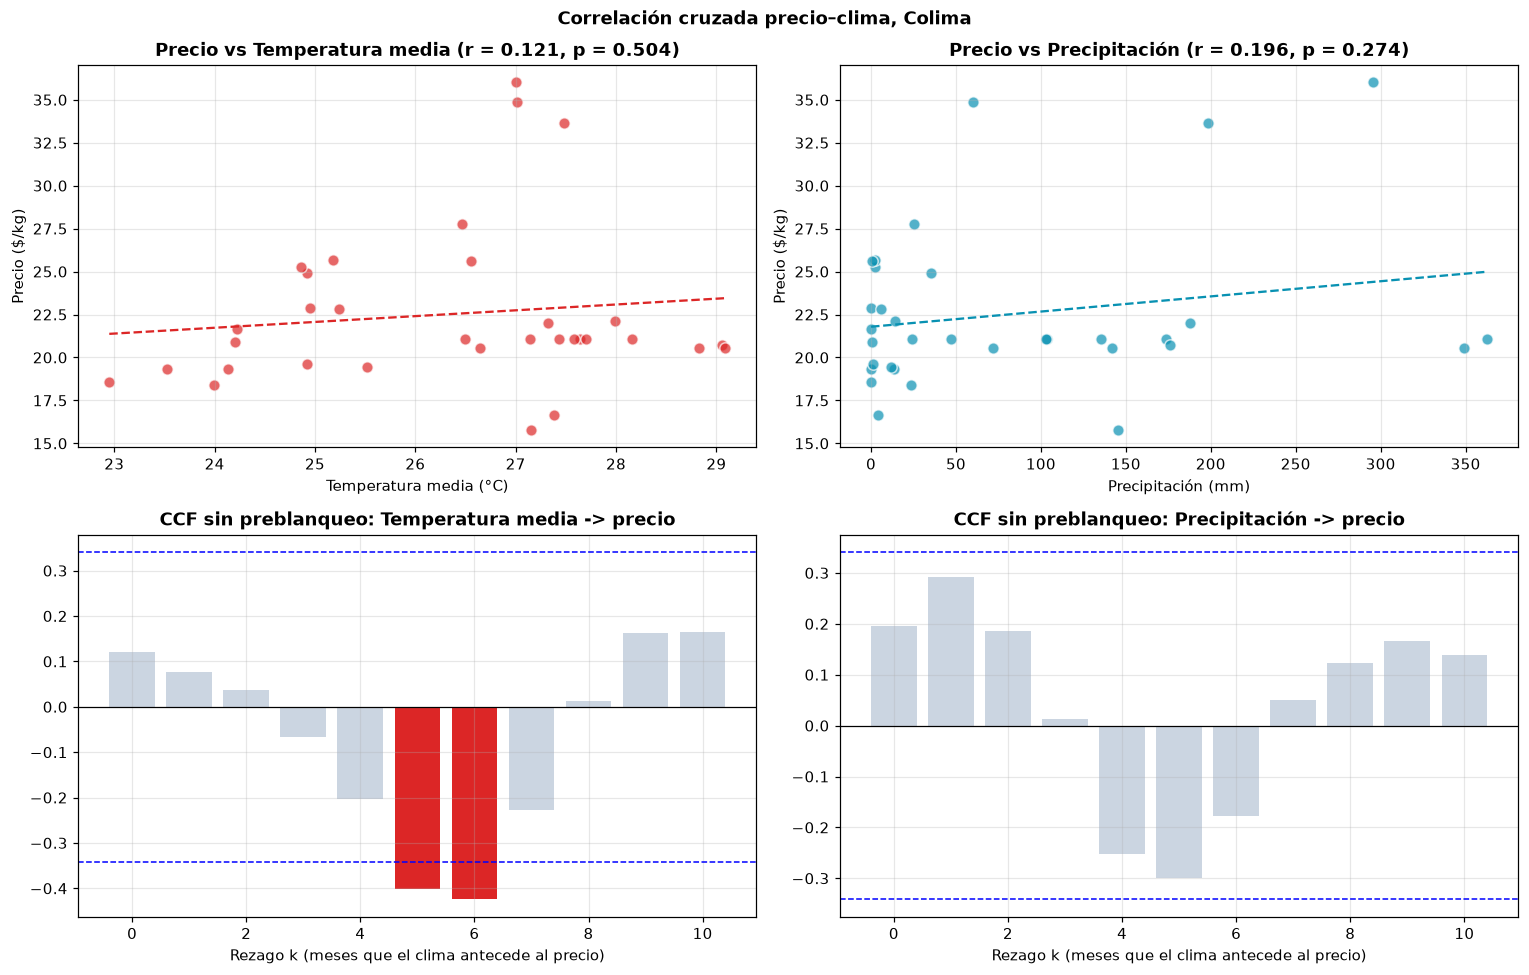

In [13]:
temp = colima["temp_media_c"]
prec = colima["precipitacion_mm"]
r_t, p_t = stats.pearsonr(temp, y)
r_p, p_p = stats.pearsonr(prec, y)
print("Correlación contemporánea (Pearson):")
print(f"  Precio–Temperatura:   r = {r_t:+.4f}, p = {p_t:.4f}")
print(f"  Precio–Precipitación: r = {r_p:+.4f}, p = {p_p:.4f}")

MAX_CCF = 10
banda_ccf = 1.96 / np.sqrt(len(y))
ccf_t = ccf(y.values, temp.values, nlags=MAX_CCF + 1)
ccf_p = ccf(y.values, prec.values, nlags=MAX_CCF + 1)
tabla_ccf = pd.DataFrame({"CCF_temperatura": ccf_t, "CCF_precipitacion": ccf_p},
                         index=pd.RangeIndex(0, MAX_CCF + 1, name="rezago")).round(4)
tabla_ccf["temp_sig"] = tabla_ccf["CCF_temperatura"].abs() > banda_ccf
tabla_ccf["prec_sig"] = tabla_ccf["CCF_precipitacion"].abs() > banda_ccf
print(f"\nCCF sin preblanqueo (banda 95 % = ±{banda_ccf:.4f}):")
print(tabla_ccf)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for col, (x, nombre, color, r, p) in enumerate([(temp, "Temperatura media (°C)", "#DC2626", r_t, p_t),
                                                  (prec, "Precipitación (mm)", "#0891B2", r_p, p_p)]):
    pend, inter, *_ = stats.linregress(x, y)
    xs = np.linspace(x.min(), x.max(), 50)
    axes[0, col].scatter(x, y, color=color, alpha=0.7, edgecolors="white", s=55)
    axes[0, col].plot(xs, inter + pend * xs, ls="--", color=color)
    axes[0, col].set_xlabel(nombre)
    axes[0, col].set_ylabel("Precio ($/kg)")
    axes[0, col].set_title(f"Precio vs {nombre.split(' (')[0]} (r = {r:.3f}, p = {p:.3f})", fontweight="bold")
    valores = tabla_ccf.iloc[:, col].values
    axes[1, col].bar(tabla_ccf.index, valores, color=[color if abs(v) > banda_ccf else "#CBD5E1" for v in valores])
    axes[1, col].axhline(banda_ccf, color="blue", ls="--", lw=1)
    axes[1, col].axhline(-banda_ccf, color="blue", ls="--", lw=1)
    axes[1, col].axhline(0, color="black", lw=0.8)
    axes[1, col].set_xlabel("Rezago k (meses que el clima antecede al precio)")
    axes[1, col].set_title(f"CCF sin preblanqueo: {nombre.split(' (')[0]} -> precio", fontweight="bold")
fig.suptitle("Correlación cruzada precio–clima, Colima", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig06_correlacion_cruzada_clima.png", bbox_inches="tight")
plt.show()

### Control de correlación espuria: preblanqueo (Box-Jenkins)
Cuando las dos series tienen autocorrelación propia (aquí el precio tiene ACF(1) = 0.75 y el clima tiene un ciclo anual), la CCF puede mostrar picos que no existen.
El procedimiento estándar es ajustar un AR a la variable climática, filtrar **las dos series con ese mismo filtro** y recalcular la CCF.

Temperatura: banda = ±0.3520 | rezagos significativos tras preblanqueo: []
   valores: [-0.039, -0.104, 0.109, -0.099, 0.105, -0.149, 0.092, 0.136, 0.208, 0.045, 0.027]
Precipitación: banda = ±0.3520 | rezagos significativos tras preblanqueo: []
   valores: [0.071, 0.228, 0.095, 0.086, -0.294, -0.137, 0.004, 0.279, 0.139, 0.136, 0.135]

Robustez — panel de 5 estados, correlación contemporánea:
  temp_media_c       r = +0.0703  p = 0.4246  n = 131
  temp_min_c         r = +0.0735  p = 0.4044  n = 131
  temp_max_c         r = +0.1314  p = 0.1345  n = 131
  precipitacion_mm   r = +0.1546  p = 0.0779  n = 131


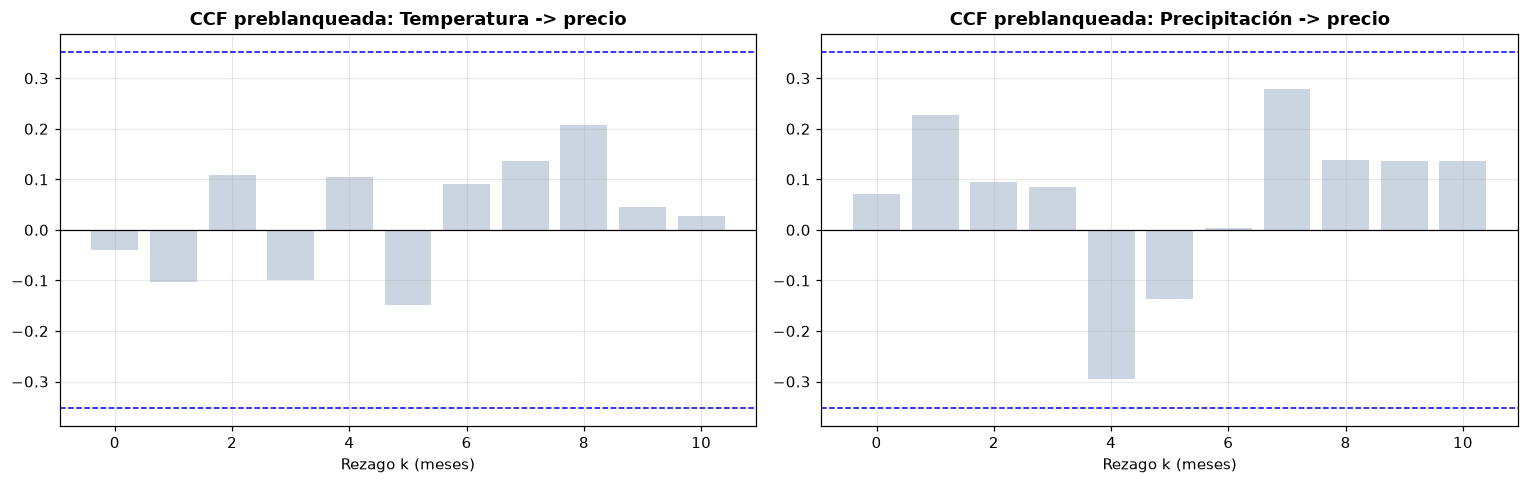

In [14]:
def preblanquear(x, y_obj, p=2):
    modelo = AutoReg(x, lags=p).fit()
    phi = modelo.params.values
    filtro = lambda s: (s - phi[0] - sum(phi[i] * s.shift(i) for i in range(1, p + 1))).dropna()
    return filtro(x), filtro(y_obj)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
resumen_pw = {}
for ax, (x, nombre, color) in zip(axes, [(temp, "Temperatura", "#DC2626"), (prec, "Precipitación", "#0891B2")]):
    xw, yw = preblanquear(x, y)
    banda_pw = 1.96 / np.sqrt(len(yw))
    valores = ccf(yw.values, xw.values, nlags=MAX_CCF + 1)
    sig = [k for k, v in enumerate(valores) if abs(v) > banda_pw]
    resumen_pw[nombre] = sig
    ax.bar(range(MAX_CCF + 1), valores, color=[color if abs(v) > banda_pw else "#CBD5E1" for v in valores])
    ax.axhline(banda_pw, color="blue", ls="--", lw=1)
    ax.axhline(-banda_pw, color="blue", ls="--", lw=1)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("Rezago k (meses)")
    ax.set_title(f"CCF preblanqueada: {nombre} -> precio", fontweight="bold")
    print(f"{nombre}: banda = ±{banda_pw:.4f} | rezagos significativos tras preblanqueo: {sig}")
    print("   valores:", np.round(valores, 3).tolist())
plt.tight_layout()
plt.savefig(FIG_DIR / "fig07_ccf_preblanqueada.png", bbox_inches="tight")
plt.show()

print("\nRobustez — panel de 5 estados, correlación contemporánea:")
for var in ["temp_media_c", "temp_min_c", "temp_max_c", "precipitacion_mm"]:
    datos = panel_lim[["precio_frec_media", var]].dropna()
    r, p = stats.pearsonr(datos[var], datos["precio_frec_media"])
    print(f"  {var:<18} r = {r:+.4f}  p = {p:.4f}  n = {len(datos)}")

**Interpretación — correlación cruzada con el clima**

- **Contemporánea:** no hay relación significativa del precio con la temperatura (**r = +0.121, p = 0.504**) ni con la precipitación (**r = +0.196, p = 0.274**). En el panel de 5 estados tampoco (temperatura media r = +0.070, p = 0.425; precipitación r = +0.155, p = 0.078).
- **CCF sin preblanqueo:**
  - *Temperatura:* aparecen dos rezagos fuera de la banda (±0.341), **k = 5 (−0.402)** y **k = 6 (−0.424)**. Sugerirían que temperaturas altas anteceden precios bajos 5–6 meses después.
  - *Precipitación:* ningún rezago es significativo. El mayor es k = 1 (+0.293).
- **Después del preblanqueo, ningún rezago es significativo** para ninguna de las dos variables. La señal de los rezagos 5–6 **era espuria**: venía de la autocorrelación propia de las series y del ciclo anual de la temperatura (6 meses es medio ciclo), no de una relación predictiva.
- **Conclusión:** con los datos disponibles **no hay evidencia de que la temperatura o la precipitación de Open-Meteo ayuden a predecir el precio**. Si el Integrante 2 prueba un ARIMAX con temperatura rezagada 5–6 meses, debe tratarlo como exploratorio y aceptarlo solo si mejora el error fuera de muestra.
- **Correlación no es causalidad.** Aunque hubiera correlación, el precio depende de factores que no están en el dataset (oferta nacional, demanda, otras regiones productoras, plagas, costos de transporte). Además, el clima corresponde a un solo punto representativo (Tecomán).

## 10. Datasets preparados

In [15]:
univariada = y.rename("precio_frec_media").rename_axis("fecha").reset_index()
univariada.to_csv(DATA_OUT / "serie_colima_univariada.csv", index=False, date_format="%Y-%m-%d")

cols_mv = ["precio_frec_media", "precio_min", "precio_max", "temp_media_c", "temp_min_c",
           "temp_max_c", "precipitacion_mm", "n_cotizaciones", "siap_imputado"]
multivariada = colima[cols_mv].rename_axis("fecha").reset_index()
multivariada.to_csv(DATA_OUT / "serie_colima_multivariada.csv", index=False, date_format="%Y-%m-%d")

cols_panel = ["anio_mes", "estado", "precio_frec_media", "precio_min", "precio_max", "temp_media_c",
              "precipitacion_mm", "produccion_ton", "siap_imputado", "mes", "trimestre", "precio_nivel"]
panel_lim[cols_panel].to_csv(DATA_OUT / "panel_5_estados.csv", index=False, date_format="%Y-%m-%d")

for nombre in ["serie_colima_univariada.csv", "serie_colima_multivariada.csv", "panel_5_estados.csv"]:
    df_chk = pd.read_csv(DATA_OUT / nombre)
    print(f"{nombre:<32} {df_chk.shape[0]:>4} filas x {df_chk.shape[1]:>2} columnas | faltantes: {int(df_chk.isna().sum().sum())}")

serie_colima_univariada.csv        33 filas x  2 columnas | faltantes: 0
serie_colima_multivariada.csv      33 filas x 10 columnas | faltantes: 0
panel_5_estados.csv               131 filas x 12 columnas | faltantes: 0


## 11. Resumen para el Integrante 2

| Elemento | Resultado |
|---|---|
| **Dataset principal** | `data/series_tiempo/serie_colima_univariada.csv` (33 filas, sin faltantes) |
| **Dataset con clima** | `data/series_tiempo/serie_colima_multivariada.csv` · panel: `panel_5_estados.csv` |
| **Variable objetivo** | `precio_frec_media` (\$/kg) · Colima |
| **Frecuencia** | Mensual (`MS`), feb 2024 – oct 2026 |
| **Descomposición** | Multiplicativa (ρ media-desviación = 0.626, p = 0.0004). Picos: ago (+14 %), sep (+16 %); valle: feb (−10 %). Patrón inestable entre años |
| **ADF (constante)** | estadístico −3.3209 · p = 0.0140 · crítico 5 % −2.9605 → estacionaria |
| **ADF (constante + tendencia)** | estadístico −3.5245 · p = 0.0368 · crítico 5 % −3.5630 → limítrofe (rechaza al 10 %) |
| **KPSS** | 0.1245 · p ≥ 0.10 → no se rechaza estacionariedad |
| **Diferenciaciones (d)** | **0** |
| **ACF** | Significativa solo en el rezago 1 (+0.750). Decaimiento oscilante; rezago 12 = −0.180 (no significativo) |
| **PACF** | Significativa en los rezagos 1 (+0.750) y 2 (−0.499); se corta después del 2; rezago 12 = −0.166 (no significativo) |
| **Orden sugerido** | **ARIMA(2,0,0) con constante** (AIC 165.23, BIC 171.22; Ljung-Box p = 0.868). Alternativas: (1,0,1) y (2,0,1). Sin evidencia para términos estacionales |
| **Correlación cruzada** | Contemporánea no significativa (temperatura r = 0.121; precipitación r = 0.196). Temperatura en rezagos 5–6 significativa sin preblanqueo (−0.402 / −0.424), pero **desaparece al preblanquear** → espuria. Precipitación: ningún rezago significativo |
| **Uso del clima** | Sin evidencia para ARIMAX. Solo exploratorio, con validación fuera de muestra |

## 12. Limitaciones

1. **Serie corta:** 33 observaciones (2.75 ciclos anuales). Limita el poder de ADF y KPSS, la estimación de factores estacionales y la detección del rezago 12.
2. **Meses parciales:** febrero 2024 y octubre 2026 tienen solo 4 cotizaciones (junio 2024, 7). Su promedio es menos representativo.
3. **Precio constante:** mayo–septiembre 2025 (21.05) y agosto–octubre 2026 (20.53) repiten el mismo precio frecuente, aunque sí hubo cotizaciones. Reducen la variabilidad observada.
4. **Episodio extremo de 2024:** agosto–noviembre 2024 domina la tendencia, la estacionalidad estimada y la relación entre dispersión y nivel.
5. **Clima puntual:** Open-Meteo representa un solo punto (Tecomán), no toda la zona productora ni los mercados de destino.
6. **Producción SIAP:** es anual (repetida por mes) y 2026 está imputada con 2025 (`siap_imputado`). No se usó como variable explicativa mensual.
7. **Correlación ≠ causalidad:** las correlaciones describen asociaciones estadísticas; no prueban efectos del clima sobre el precio.
8. **Pruebas múltiples:** al revisar 11 rezagos por variable, algunos pueden parecer significativos por azar. Por eso se usó preblanqueo.
9. **Panel desbalanceado:** Yucatán tiene 1 solo mes y Guerrero 29. El panel de 5 estados solo se usó como chequeo de robustez de la correlación con el clima, no como serie para modelar.